# Differentialgleichungen

Das Notebook behandelt gewöhnliche und partielle Differentialgleichungen an Beispielen aus der Physik: exakte Lösungen mit sympy, lineare Systeme mit dem Matrixexponential und ihre Phasenporträts, numerische Integratoren (Euler, Runge-Kutta, symplektisch) mit Konvergenzordnung und Energieerhaltung, steife Gleichungen, ein Eigenwertproblem, die Wärmeleitungs- und die Wellengleichung mit finiten Differenzen und ihren Stabilitätsgrenzen, die Schrödinger-Gleichung mit dem Split-Step-Fourier-Verfahren am Tunneleffekt und die Stabilitätskarte der Mathieu-Gleichung (Floquet-Theorie, parametrische Resonanz).

Wie löst man Differentialgleichungen, analytisch, wo es geht, und numerisch, wo es nicht geht, und woran erkennt man, ob eine numerische Lösung stimmt?

#### **Hintergrund**

Differentialgleichungen sind die Sprache, in der die Naturgesetze geschrieben sind: Sie sagen nicht, wo etwas ist, sondern wie es sich ändert. Newtons Bewegungsgesetz (1687), d'Alemberts Wellengleichung (1747), Fouriers Wärmeleitungsgleichung (1822), die Maxwell-Gleichungen und die Schrödinger-Gleichung (1926) sind alle von dieser Art. Nur wenige lassen sich geschlossen lösen; fast alle Gleichungen der Praxis löst man numerisch. Damit beginnen eigene Fragen: Wie schnell wird der Fehler kleiner, wenn man die Schrittweite verkleinert? Bleiben kleine Fehler klein? Erhält das Verfahren, was die Gleichung erhält?

Die numerischen Grundlagen stammen von Runge (1895) und Kutta (1901), Courant, Friedrichs und Lewy (1928, Stabilität von Gitterverfahren), von Neumann (Fourier-Analyse der Stabilität), Verlet (1967, Molekulardynamik) und den Arbeiten über steife und symplektische Verfahren ab den 1960er Jahren. Heute stecken Differentialgleichungen in Wettermodellen, Crashsimulationen, Schaltkreisen und Epidemiemodellen. Im maschinellen Lernen sind Neural ODEs und Diffusionsmodelle (stochastische Differentialgleichungen) eigene Modellklassen, und physikinformierte Netze lernen Lösungen partieller Gleichungen. In der Quantensimulation ist die Trotter-Zerlegung der Zeitentwicklung dasselbe wie das Split-Step-Verfahren dieses Notebooks.

Landkarte:

- **Gewöhnliche Differentialgleichungen**
  - Exakte Lösungen (Exp. 1): gedämpfter Oszillator und logistisches Wachstum mit sympy, Probe durch Einsetzen.
  - Lineare Systeme (Exp. 2): $x(t) = e^{At}x_0$; Spur und Determinante von $A$ entscheiden zwischen Knoten, Sattel, Spirale und Zentrum.
- **Numerische Verfahren**
  - Integratoren (Exp. 3): Euler hat Ordnung 1, Runge–Kutta Ordnung 4; symplektische Verfahren halten die Energie über lange Zeiten.
  - Steife Gleichungen (Exp. 4): Explizite Verfahren brauchen winzige Schritte, implizite nicht.
- **Eigenwertprobleme**
  - Quantenmechanischer Oszillator (Exp. 5): Finite Differenzen machen aus der Gleichung eine Matrix; der Fehler der Energien fällt wie $\Delta x^2$.
- **Partielle Differentialgleichungen**
  - Wärmeleitung (Exp. 6): Fourier-Reihe gegen finite Differenzen; stabil nur für $r = \alpha\Delta t/\Delta x^2\leq\tfrac12$.
  - Wellengleichung (Exp. 7): d'Alembert, Leapfrog und die CFL-Bedingung $C\leq1$.
  - Schrödinger-Gleichung (Exp. 8): Split-Step-Fourier, Tunneln durch eine Barriere.
- **Periodischer Antrieb**
  - Floquet-Theorie (Exp. 9): die Stabilitätskarte der Mathieu-Gleichung, parametrische Resonanz bei $a = n^2$.

Verwandte Notebooks: Fixpunkte, Stabilität und Chaos nichtlinearer Systeme in [Dynamische Systeme und Chaos](https://github.com/deltorobarba/science/blob/main/maths/chaos.ipynb), die Laplace-Transformation in [Funktionentheorie](https://github.com/deltorobarba/science/blob/main/maths/complexanalysis.ipynb), Volumenerhaltung im Phasenraum (Liouville) in [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb), die Euler–Lagrange-Gleichung als Quelle vieler Differentialgleichungen in [Variationsrechnung](https://github.com/deltorobarba/science/blob/main/maths/calculus_of_variations.ipynb).

#### **Theorie**

##### *1. Begriffe, Existenz und Eindeutigkeit*

Eine **gewöhnliche Differentialgleichung** (ODE) verknüpft eine Funktion einer Variablen mit ihren Ableitungen, etwa $\ddot x = -\omega^2x$; eine **partielle** (PDE) enthält Ableitungen nach mehreren Variablen, etwa $\partial_tu = \alpha\,\partial_x^2u$. Die **Ordnung** ist die höchste Ableitung; **linear** heißt, die Funktion und ihre Ableitungen kommen nur in erster Potenz vor, und Lösungen lassen sich überlagern. Ein **Anfangswertproblem** legt den Zustand zu einer Zeit fest, ein **Randwertproblem** Werte am Rand eines Gebiets; gibt es Lösungen nur für bestimmte Werte eines Parameters, ist es ein **Eigenwertproblem** (etwa die erlaubten Energien der Quantenmechanik).

Für $\dot y = f(t, y)$, $y(t_0) = y_0$ gibt es genau eine Lösung, wenn $f$ stetig ist und in $y$ einer **Lipschitz-Bedingung** genügt (**Satz von Picard–Lindelöf**); der Beweis iteriert die Integralgleichung $y(t) = y_0 + \int_{t_0}^tf(s, y(s))\,ds$. Ohne Lipschitz-Bedingung kann die Eindeutigkeit fehlen: $\dot y = \sqrt y$, $y(0) = 0$ hat die Lösungen $y = 0$ und $y = t^2/4$.

##### *2. Lineare Systeme, Oszillator, logistisches Wachstum*

Für $\dot x = Ax$ ist $x(t) = e^{At}x_0$ mit dem **Matrixexponential** $e^{At} = \sum_k(At)^k/k!$. Ist $A = PDP^{-1}$ diagonalisierbar, ist $e^{At} = Pe^{Dt}P^{-1}$, eine Überlagerung von $e^{\mu_kt}$ mit den Eigenwerten $\mu_k$. In zwei Dimensionen entscheiden **Spur** $\tau$ und **Determinante** $\Delta$: $\Delta<0$ gibt einen **Sattel**; für $\Delta>0$ ist der Fixpunkt stabil, wenn $\tau<0$; bei $\tau^2<4\Delta$ sind die Eigenwerte komplex und die Bahnen **Spiralen**, bei $\tau^2>4\Delta$ ein **Knoten**, bei $\tau = 0$ geschlossene Ellipsen (**Zentrum**).

Der **gedämpfte Oszillator** $\ddot x + 2\gamma\dot x + \omega_0^2x = 0$ gibt mit $x = e^{\lambda t}$ die Gleichung $\lambda^2 + 2\gamma\lambda + \omega_0^2 = 0$, also $\lambda = -\gamma\pm\sqrt{\gamma^2 - \omega_0^2}$: schwach gedämpft eine Schwingung mit $\omega = \sqrt{\omega_0^2 - \gamma^2}$, stark gedämpft zwei abklingende Exponentialfunktionen, im **aperiodischen Grenzfall** $\gamma = \omega_0$ die Lösung $(c_1 + c_2t)e^{-\gamma t}$, die schnellste Rückkehr ohne Überschwingen. Die **logistische Gleichung** $\dot N = rN(1 - N/K)$ beschreibt Wachstum mit begrenzten Ressourcen; ihre Lösung ist $N(t) = KN_0e^{rt}/(K + N_0(e^{rt} - 1))$.

##### *3. Numerische Integratoren: Ordnung, Stabilität, Steifheit, Symplektik*

- **Ordnung:** Das explizite **Euler-Verfahren** $y_{n+1} = y_n + hf(y_n)$ bricht die Taylor-Reihe nach dem ersten Glied ab; der Fehler pro Schritt ist $O(h^2)$, nach $T/h$ Schritten $O(h)$: Ordnung 1. Das klassische **Runge–Kutta-Verfahren** mittelt vier Steigungen so, dass die Taylor-Reihe bis $h^4$ stimmt: Ordnung 4. Im doppelt logarithmischen Plot von Fehler gegen $h$ ist die Ordnung die Steigung.
- **Stabilität:** An der Testgleichung $\dot y = \lambda y$ mit $\lambda<0$ gibt Euler $y_{n+1} = (1 + h\lambda)y_n$, beschränkt nur für $h\leq2/\vert\lambda\vert$. Das **implizite** Euler-Verfahren $y_{n+1} = y_n + hf(y_{n+1})$ gibt $y_{n+1} = y_n/(1 - h\lambda)$ und ist für jedes $h$ stabil, verlangt aber pro Schritt das Lösen einer Gleichung.
- **Steifheit:** Eine Gleichung heißt **steif**, wenn sie sehr schnelle und langsame Vorgänge enthält. Explizite Verfahren müssen dann die schnelle Zeitskala mit winzigen Schritten auflösen, auch wenn der schnelle Vorgang längst abgeklungen ist; implizite Verfahren (etwa Radau) nicht.
- **Symplektische Verfahren:** Für den Oszillator $\ddot x = -x$ ist ein Euler-Schritt die Matrix $\begin{pmatrix}1 & h\\ -h & 1\end{pmatrix}$ mit Determinante $1 + h^2$: Jeder Schritt vergrößert Flächen im Phasenraum, die Energie wächst wie $(1 + h^2)^{t/h}\approx e^{ht}$. Das **symplektische Euler-Verfahren** berechnet erst $v_{n+1} = v_n - hx_n$, dann $x_{n+1} = x_n + hv_{n+1}$; seine Matrix hat Determinante 1 und erhält Flächen wie die exakte Lösung (**Satz von Liouville**). Die Energie schwankt dann für alle Zeiten nur um $O(h)$, weil das Verfahren eine leicht veränderte Energie exakt erhält. **Störmer–Verlet** ist die symmetrische Variante mit Ordnung 2 (Planetenbahnen, Molekulardynamik). Runge–Kutta 4 ist pro Schritt genauer, aber nicht symplektisch; seine Energie driftet langsam.

##### *4. Partielle Differentialgleichungen*

Für $Au_{xx} + 2Bu_{xy} + Cu_{yy} + \dots = 0$ entscheidet das Vorzeichen von $B^2 - AC$ über den **Typ**:
- **elliptisch** ($<0$; Laplace, Poisson): Gleichgewichte, glatte Lösungen, jeder Punkt hängt vom ganzen Rand ab;
- **parabolisch** ($=0$; Wärmeleitung $u_t = \alpha u_{xx}$): Ausgleich, Kanten werden sofort geglättet;
- **hyperbolisch** ($>0$; Welle $u_{tt} = c^2u_{xx}$): Ausbreitung mit endlicher Geschwindigkeit entlang der **Charakteristiken** $x\pm ct = \text{const}$, Kanten bleiben erhalten.

**Wärmeleitung:** Auf $[0, 1]$ mit $u = 0$ am Rand führt die **Trennung der Variablen** $u = X(x)T(t)$ auf $u = \sum_nb_n\sin(n\pi x)\,e^{-\alpha n^2\pi^2t}$ mit $b_n = 2\int_0^1u(x, 0)\sin(n\pi x)\,dx$. Hohe Moden zerfallen wie $e^{-n^2t}$, deshalb wird jede Kante sofort geglättet. Das explizite Gitterverfahren **FTCS** (vorwärts in der Zeit, zentral im Raum) ist $u_j^{n+1} = u_j^n + r(u_{j+1}^n - 2u_j^n + u_{j-1}^n)$ mit $r = \alpha\Delta t/\Delta x^2$. Die **von-Neumann-Analyse** setzt eine Fourier-Mode ein: Sie wird pro Schritt mit $g = 1 - 4r\sin^2(k\Delta x/2)$ multipliziert, die kürzeste Gitterwelle mit $1 - 4r$. Stabil ist das nur für $r\leq\tfrac12$; halbiert man $\Delta x$, muss $\Delta t$ auf ein Viertel sinken.

**Welle:** Die allgemeine Lösung von $u_{tt} = c^2u_{xx}$ ist $F(x - ct) + G(x + ct)$ (**d'Alembert**), zwei Formen, die ungeändert nach rechts und links laufen. Das **Leapfrog-Verfahren** $u_j^{n+1} = 2u_j^n - u_j^{n-1} + C^2(u_{j+1}^n - 2u_j^n + u_{j-1}^n)$ mit der **Courant-Zahl** $C = c\Delta t/\Delta x$ ist stabil für $C\leq1$ (**CFL-Bedingung**, Courant, Friedrichs, Lewy 1928): In einem Zeitschritt darf die Welle nicht weiter laufen als eine Gitterzelle. Bei $C = 1$ ist das Verfahren auf den Gitterpunkten exakt, weil die Charakteristiken genau durch Gitterpunkte laufen; bei $C<1$ laufen kurze Wellen etwas zu langsam (**numerische Dispersion**).

**Eigenwertprobleme auf dem Gitter:** Ersetzt man $\psi''$ durch $(\psi_{j+1} - 2\psi_j + \psi_{j-1})/\Delta x^2$, wird aus $-\tfrac12\psi'' + V\psi = E\psi$ eine tridiagonale Matrix, deren Eigenwerte die Energien nähern; der Fehler fällt wie $\Delta x^2$.

##### *5. Schrödinger-Gleichung mit Split-Step-Fourier*

Mit $\hbar = m = 1$ ist $i\psi_t = H\psi$, $H = T + V$, $T = -\tfrac12\partial_x^2$. Die Zeitentwicklung $e^{-iH\Delta t}$ lässt sich nicht direkt ausrechnen, weil $T$ und $V$ nicht vertauschen. Die symmetrische Zerlegung (**Strang-Splitting**)
$$e^{-iH\Delta t} = e^{-iV\Delta t/2}\,e^{-iT\Delta t}\,e^{-iV\Delta t/2} + O(\Delta t^3)$$
folgt aus der **Baker–Campbell–Hausdorff-Formel**; der Fehler zweiter Ordnung hebt sich durch die Symmetrie weg. Die Faktoren mit $V$ sind im Ortsraum diagonal, der mit $T$ im Impulsraum ($e^{-ik^2\Delta t/2}$); dazwischen wechselt die FFT. Jeder Faktor ist unitär, die Norm bleibt exakt erhalten. Für eine Stufe der Höhe $V_0$ und Breite $a$ ist die Transmission einer ebenen Welle mit Energie $E<V_0$
$$\mathcal T(E) = \left[1 + \frac{V_0^2\sinh^2(\kappa a)}{4E(V_0 - E)}\right]^{-1},\qquad\kappa = \sqrt{2(V_0 - E)} .$$
Ein Wellenpaket enthält eine Spanne von Impulsen; seine Transmission ist das Mittel von $\mathcal T$ über diese Spanne, und weil $\mathcal T$ steil mit $E$ wächst, tragen die energiereicheren Anteile mehr bei.

##### *6. Floquet-Theorie und parametrische Resonanz*

Für $\ddot x + q(t)x = 0$ mit periodischem $q(t + T) = q(t)$ bildet die **Monodromiematrix** $M$ den Zustand $(x, \dot x)$ über eine Periode ab. Ohne Dämpfung ist $\det M = 1$ (Liouville). Die Eigenwerte erfüllen $\mu^2 - (\mathrm{tr}\,M)\mu + 1 = 0$: Ist $\vert\mathrm{tr}\,M\vert<2$, liegen sie auf dem Einheitskreis und alle Lösungen bleiben beschränkt; ist $\vert\mathrm{tr}\,M\vert>2$, ist einer größer als 1, und Lösungen wachsen exponentiell. Bei der **Mathieu-Gleichung** $\ddot x + (a - 2q\cos2t)x = 0$ entstehen instabile **Zungen**, die bei $q = 0$ an den Punkten $a = n^2$ beginnen und für kleine $q$ nur etwa $q^n$ breit sind. Schwingt der Parameter mit der doppelten Eigenfrequenz, schaukelt sich die Schwingung auf (**parametrische Resonanz**), wie beim Anschwingen einer Schaukel durch Heben und Senken des Körpers.

#### **Code**

Gemeinsame Werkzeuge: Schritte der Integratoren und ein vektorisierter Runge-Kutta-Schritt.

In [1]:
# Alles hier (numpy, scipy, sympy, matplotlib) ist in Colab vorinstalliert
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import expm, eigh_tridiagonal

def rk4(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def integrate_oscillator(method, h, T):
    """x'' = −x mit x(0) = 1, v(0) = 0; gibt Zeiten, x und Energie zurück."""
    n = int(round(T / h))
    x, v = 1.0, 0.0
    xs, es = [x], [0.5 * (x * x + v * v)]
    for _ in range(n):
        if method == "Euler":
            x, v = x + h * v, v - h * x
        elif method == "symplektischer Euler":
            v = v - h * x
            x = x + h * v
        elif method == "Störmer-Verlet":
            v_half = v - h / 2 * x
            x = x + h * v_half
            v = v_half - h / 2 * x
        elif method == "Runge-Kutta 4":
            x, v = rk4(lambda t, y: np.array([y[1], -y[0]]), 0.0, np.array([x, v]), h)
        xs.append(x)
        es.append(0.5 * (x * x + v * v))
    return np.arange(n + 1) * h, np.array(xs), np.array(es)

print("Werkzeuge bereit")

Werkzeuge bereit


#### **Experimente**

##### *1. Exakte Lösungen mit sympy*

Welche geschlossenen Lösungen haben der gedämpfte Oszillator und die logistische Gleichung, und erfüllen sie ihre Gleichungen? Vorher vorhersagen: Welche Form hat die Lösung im aperiodischen Grenzfall $\gamma = \omega_0$?

`dsolve` löst die Gleichungen symbolisch, und `checkodesol` setzt die Lösung in die Gleichung ein und prüft, ob die Differenz null ist.

**Hintergrund & Fachbegriffe:**
- **Geschlossene Lösung:** eine Formel aus bekannten Funktionen, die die Gleichung für alle Zeiten löst. Sie gibt es nur für wenige, meist lineare Gleichungen.
- **Gedämpfter Oszillator:** $\ddot x + 2\gamma\dot x + \omega_0^2x = 0$, eine Masse an einer Feder mit Reibung; $\gamma$ ist die Dämpfung, $\omega_0$ die Eigenfrequenz.
- **Logistische Gleichung:** $\dot N = rN(1 - N/K)$, Wachstum mit Rate $r$, das bei der Kapazität $K$ zum Stillstand kommt.
- **Probe durch Einsetzen:** Man setzt die gefundene Lösung in die Gleichung ein und vereinfacht; bleibt null übrig, stimmt sie.

In [2]:
t = sp.symbols("t", positive=True)
gam, w0, r_, K_, N0 = sp.symbols("gamma omega_0 r K N_0", positive=True)
x = sp.Function("x")
Nf = sp.Function("N")

osc = sp.Eq(x(t).diff(t, 2) + 2 * gam * x(t).diff(t) + w0 ** 2 * x(t), 0)
sol_osc = sp.dsolve(osc, x(t))
print("Gedämpfter Oszillator:")
display(sol_osc)
print("Aperiodischer Grenzfall γ = ω₀:")
display(sp.dsolve(osc.subs(gam, w0), x(t)))

logi = sp.Eq(Nf(t).diff(t), r_ * Nf(t) * (1 - Nf(t) / K_))
sol_logi = sp.dsolve(logi, Nf(t), ics={Nf(0): N0})
print("Logistische Gleichung mit N(0) = N₀:")
display(sp.simplify(sol_logi))
print("Probe durch Einsetzen (checkodesol):", sp.checkodesol(osc, sol_osc)[0], sp.checkodesol(logi, sol_logi)[0])

Gedämpfter Oszillator:


Eq(x(t), C1*exp(t*(-gamma + sqrt(gamma - omega_0)*sqrt(gamma + omega_0))) + C2*exp(-t*(gamma + sqrt(gamma - omega_0)*sqrt(gamma + omega_0))))

Aperiodischer Grenzfall γ = ω₀:


Eq(x(t), (C1 + C2*t)*exp(-omega_0*t))

Logistische Gleichung mit N(0) = N₀:


Eq(N(t), K*N_0*exp(r*t)/(K + N_0*exp(r*t) - N_0))

Probe durch Einsetzen (checkodesol): True True


* Die **Ausgabe** zeigt die Lösungen, die sympy findet: für den Oszillator Exponentialfunktionen mit $\lambda = -\gamma\pm\sqrt{\gamma^2 - \omega_0^2}$, im aperiodischen Grenzfall $(C_1 + C_2t)e^{-\omega_0t}$ und für die logistische Gleichung $N(t) = KN_0e^{rt}/(K + N_0(e^{rt} - 1))$, eine S-Kurve von $N_0$ nach $K$.
* `checkodesol` gibt für beide Gleichungen `True`: Die Lösungen erfüllen ihre Gleichungen. Im aperiodischen Grenzfall fallen die beiden Exponenten zusammen; der Faktor $t$ ersetzt dann die zweite, fehlende Lösung.

##### *2. Lineare Systeme: Matrixexponential und Phasenporträts*

Wie sehen die Bahnen von $\dot x = Ax$ für verschiedene Matrizen aus, und stimmt $e^{At}x_0$ mit einer numerischen Lösung überein? Vorher vorhersagen: Welche Matrix gibt geschlossene Bahnen?

Vier Matrizen, je eine für Knoten, Sattel, Spirale und Zentrum (Abschnitt 2 der Theorie). Für jede werden das Richtungsfeld, eine Bahn aus $e^{At}x_0$ und die Abweichung zu `solve_ivp` gezeigt, dazu Spur, Determinante und $\tau^2 - 4\Delta$.

**Hintergrund & Fachbegriffe:**
- **Phasenporträt:** die Bahnen eines Systems in der Ebene seiner Zustände, mit Pfeilen in Bewegungsrichtung.
- **Matrixexponential:** $e^{At} = \sum_k(At)^k/k!$; es bildet den Anfangszustand auf den Zustand zur Zeit $t$ ab, $x(t) = e^{At}x_0$.
- **Knoten, Sattel, Spirale, Zentrum:** die vier Grundformen eines linearen Fixpunkts. Knoten: alle Bahnen laufen direkt hinein (reelle Eigenwerte gleichen Vorzeichens). Sattel: hinein in einer, hinaus in der anderen Richtung. Spirale: komplexe Eigenwerte mit Realteil ungleich null. Zentrum: rein imaginäre Eigenwerte, geschlossene Bahnen.
- **Spur und Determinante:** Summe und Produkt der Eigenwerte; aus ihnen liest man in zwei Dimensionen den Typ ab.

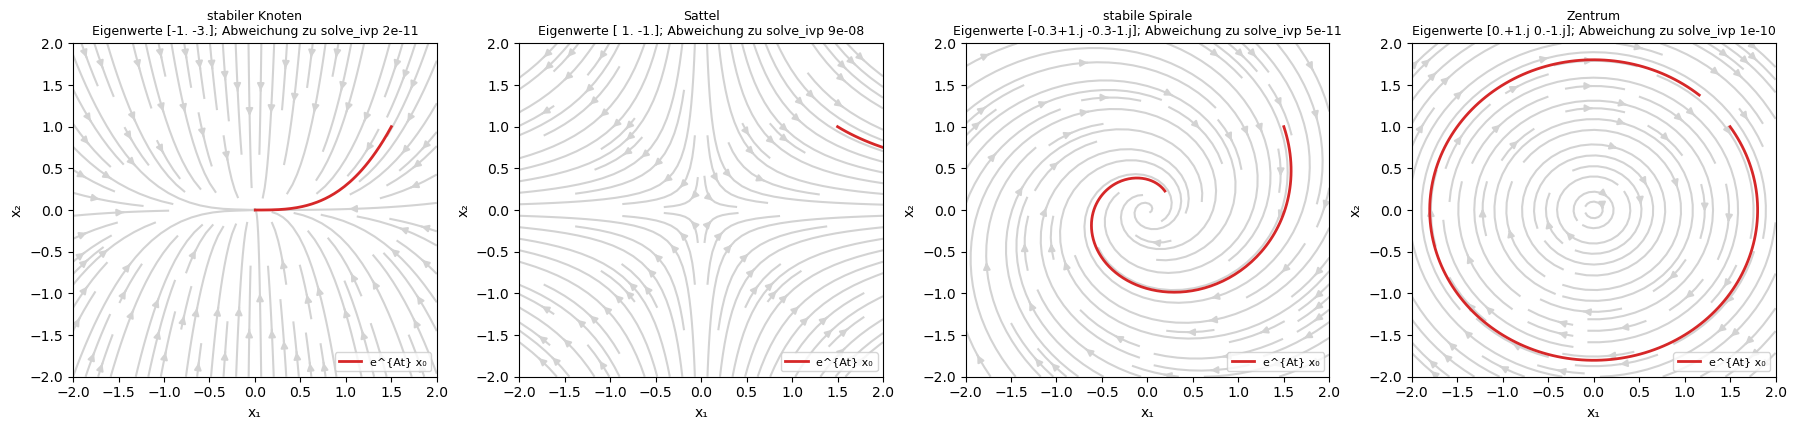

stabiler Knoten : Spur τ = -4.0, Determinante Δ = +3.00, τ² − 4Δ = +4.00
Sattel          : Spur τ = +0.0, Determinante Δ = -1.00, τ² − 4Δ = +4.00
stabile Spirale : Spur τ = -0.6, Determinante Δ = +1.09, τ² − 4Δ = -4.00
Zentrum         : Spur τ = +0.0, Determinante Δ = +1.00, τ² − 4Δ = -4.00


In [3]:
cases = {"stabiler Knoten": np.array([[-1.0, 0.0], [0.0, -3.0]]),
         "Sattel": np.array([[1.0, 0.0], [0.0, -1.0]]),
         "stabile Spirale": np.array([[-0.3, 1.0], [-1.0, -0.3]]),
         "Zentrum": np.array([[0.0, 1.0], [-1.0, 0.0]])}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
Xg, Yg = np.meshgrid(np.linspace(-2, 2, 25), np.linspace(-2, 2, 25))
for ax, (name, A) in zip(axes, cases.items()):
    U, V = A[0, 0] * Xg + A[0, 1] * Yg, A[1, 0] * Xg + A[1, 1] * Yg
    ax.streamplot(Xg, Yg, U, V, color="lightgrey", density=1.0)
    x0 = np.array([1.5, 1.0])
    ts = np.linspace(0, 6, 200)
    path = np.array([expm(A * s) @ x0 for s in ts])
    ax.plot(*path.T, c="tab:red", lw=2, label="e^{At} x₀")
    num = solve_ivp(lambda s, y: A @ y, [0, 6], x0, t_eval=ts, rtol=1e-10, atol=1e-12)
    err = np.max(np.abs(num.y.T - path))
    mu = np.linalg.eigvals(A)
    ax.set_title(f"{name}\nEigenwerte {np.round(mu, 2)}; Abweichung zu solve_ivp {err:.0e}", fontsize=9)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
for name, A in cases.items():
    print(f"{name:16s}: Spur τ = {np.trace(A):+.1f}, Determinante Δ = {np.linalg.det(A):+.2f}, τ² − 4Δ = {np.trace(A) ** 2 - 4 * np.linalg.det(A):+.2f}")

* Die **vier Bilder** zeigen die Richtungsfelder (grau) und je eine Bahn ab $(1.5, 1)$ (rot). Beim stabilen Knoten (Eigenwerte $-1$ und $-3$) läuft sie ohne Drehung in den Ursprung, zuletzt entlang der langsamen Richtung. Beim Sattel (Eigenwerte $\pm1$) läuft sie entlang der instabilen Richtung nach kurzer Zeit aus dem Bild. Bei der stabilen Spirale ($-0.3\pm i$) dreht sie sich nach innen, beim Zentrum ($\pm i$) läuft sie auf einer geschlossenen Bahn.
* Die **Ausgabe** gibt Spur, Determinante und $\tau^2 - 4\Delta$: Der Sattel hat $\Delta = -1<0$, die Spirale $\tau^2 - 4\Delta = -4<0$ mit $\tau = -0.6$, das Zentrum $\tau = 0$ und $\Delta>0$, der Knoten $\tau^2 - 4\Delta = +4>0$. Das Matrixexponential stimmt mit `solve_ivp` auf $10^{-11}$ bis $10^{-7}$ überein (Titel); beim Sattel ist die Abweichung am größten, weil die Lösung dort exponentiell wächst.

##### *3. Integratoren: Energie über lange Zeiten und Ordnung der Konvergenz*

Wie entwickelt sich die Energie eines Oszillators über 200 Zeiteinheiten bei Euler, symplektischem Euler, Störmer–Verlet und Runge–Kutta 4, und mit welcher Potenz von $h$ fällt der Fehler? Vorher vorhersagen: Um welchen Faktor wächst die Energie beim expliziten Euler-Verfahren in 200 Zeiteinheiten mit $h = 0.1$?

Der Oszillator ist $\ddot x = -x$ mit $x(0) = 1$, $\dot x(0) = 0$. Links: relativer Energiefehler mit Schrittweite $h = 0.1$. Rechts: Fehler im Ort nach $T = 10$ gegen die Schrittweite; die Steigung im doppelt logarithmischen Plot ist die Ordnung.

**Hintergrund & Fachbegriffe:**
- **Ordnung eines Verfahrens:** Der Fehler am Ende fällt wie $h^p$; $p$ ist die Ordnung. Halbiert man $h$, wird der Fehler $2^p$-mal kleiner.
- **Euler, symplektischer Euler, Störmer–Verlet, Runge–Kutta 4:** vier Verfahren mit den Ordnungen 1, 1, 2 und 4. Die beiden mittleren sind **symplektisch**: Sie erhalten Flächen im Phasenraum wie die exakte Lösung.
- **Energiefehler:** $\vert E(t)/E(0) - 1\vert$; bei einem symplektischen Verfahren bleibt er für alle Zeiten beschränkt, bei den anderen wächst er.

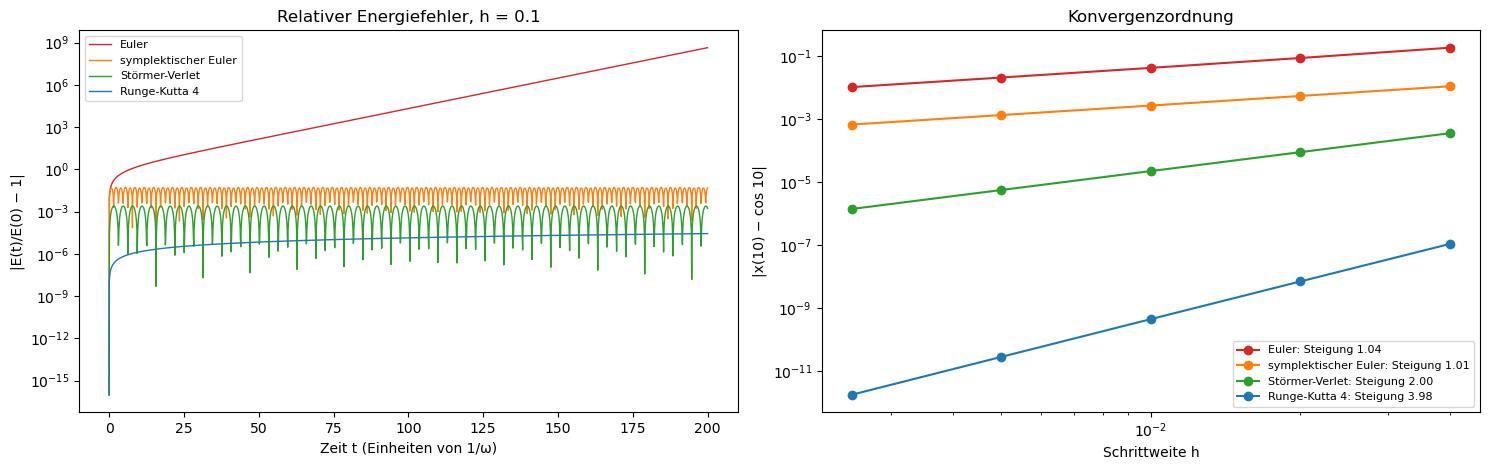

Euler                : Ordnung 1.04;  E(200)/E(0) = 4.393e+08
symplektischer Euler : Ordnung 1.01;  E(200)/E(0) = 1.05
Störmer-Verlet       : Ordnung 2.00;  E(200)/E(0) = 0.9983
Runge-Kutta 4        : Ordnung 3.98;  E(200)/E(0) = 1
Vorhersage für Euler: (1 + h²)^(T/h) = 4.393e+08


In [4]:
METHODS = ["Euler", "symplektischer Euler", "Störmer-Verlet", "Runge-Kutta 4"]
COLORS = ["tab:red", "tab:orange", "tab:green", "tab:blue"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for m, c in zip(METHODS, COLORS):
    ts, xs, es = integrate_oscillator(m, 0.1, 200)
    axes[0].semilogy(ts, np.abs(es / 0.5 - 1) + 1e-16, c=c, lw=1, label=m)
axes[0].set_xlabel("Zeit t (Einheiten von 1/ω)")
axes[0].set_ylabel("|E(t)/E(0) − 1|")
axes[0].set_title("Relativer Energiefehler, h = 0.1")
axes[0].legend(fontsize=8)

hs = np.array([0.04, 0.02, 0.01, 0.005, 0.0025])
orders = {}
for m, c in zip(METHODS, COLORS):
    errs = [abs(integrate_oscillator(m, h, 10)[1][-1] - np.cos(10)) for h in hs]
    orders[m] = np.polyfit(np.log(hs), np.log(errs), 1)[0]
    axes[1].loglog(hs, errs, "o-", c=c, label=f"{m}: Steigung {orders[m]:.2f}")
axes[1].set_xlabel("Schrittweite h")
axes[1].set_ylabel("|x(10) − cos 10|")
axes[1].set_title("Konvergenzordnung")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
for m in METHODS:
    e_end = integrate_oscillator(m, 0.1, 200)[2][-1] / 0.5
    print(f"{m:21s}: Ordnung {orders[m]:.2f};  E(200)/E(0) = {e_end:.4g}")
print(f"Vorhersage für Euler: (1 + h²)^(T/h) = {(1 + 0.01) ** 2000:.4g}")

* Das **linke Bild** zeigt den Energiefehler auf logarithmischer Skala. Beim expliziten Euler-Verfahren (rot) wächst er stetig und exponentiell, bis auf $10^9$. Der symplektische Euler (orange) und Störmer–Verlet (grün) schwanken in einem festen Band, um einige Prozent bzw. Promille, ohne zu wachsen. Runge–Kutta 4 (blau) ist viel genauer, driftet aber langsam und stetig nach oben, weil es nicht symplektisch ist.
* Das **rechte Bild** zeigt den Fehler im Ort gegen $h$: vier Geraden mit den Steigungen $1.04$, $1.01$, $2.00$ und $3.98$, also den Ordnungen 1, 1, 2 und 4. Runge–Kutta 4 ist bei $h = 0.02$ schon auf $10^{-12}$ genau.
* Die **Ausgabe** gibt $E(200)/E(0)$: $4.39\cdot10^8$ für Euler, genau die Vorhersage $(1 + h^2)^{T/h} = 1.01^{2000}$; $1.05$ für den symplektischen Euler, $0.998$ für Störmer–Verlet und $1$ für Runge–Kutta 4 (die Drift ist dort erst $10^{-5}$). Für lange Rechnungen zählt nicht nur die Ordnung, sondern ob das Verfahren die Struktur der Gleichung erhält.

##### *4. Eine steife Gleichung*

Warum braucht das explizite Euler-Verfahren für $\dot y = -1000\,(y - \cos t)$ winzige Schritte, obwohl die Lösung sich langsam ändert? Vorher vorhersagen: Bei welcher Schrittweite kippt das Verfahren?

Nach einem kurzen Einschwingen folgt $y$ fast genau $\cos t$; die schnelle Zeitskala $1/1000$ ist dann bedeutungslos. Das explizite Euler-Verfahren läuft mit $h = 0.0019$ und $0.0021$, knapp unter und über der Grenze $2/1000$, das implizite mit $h = 0.02$. Dazu vergleichen zwei adaptive Verfahren aus scipy die Zahl der Auswertungen bis $t = 10$.

**Hintergrund & Fachbegriffe:**
- **Steife Gleichung:** enthält eine sehr schnelle und eine langsame Zeitskala. Die Lösung folgt nach kurzer Zeit der langsamen, aber explizite Verfahren müssen trotzdem die schnelle auflösen, sonst werden sie instabil.
- **Stabilitätsgrenze:** Für $\dot y = \lambda y$ ist explizites Euler nur für $h\leq2/\vert\lambda\vert$ stabil, hier $h\leq0.002$.
- **Implizites Verfahren:** berechnet den neuen Wert aus einer Gleichung, in der er selbst vorkommt; für lineare Gleichungen ist es für jedes $h$ stabil.
- **Adaptive Schrittweite:** RK45 (explizit) und Radau (implizit) wählen ihre Schrittweite selbst so, dass ein vorgegebener Fehler eingehalten wird.

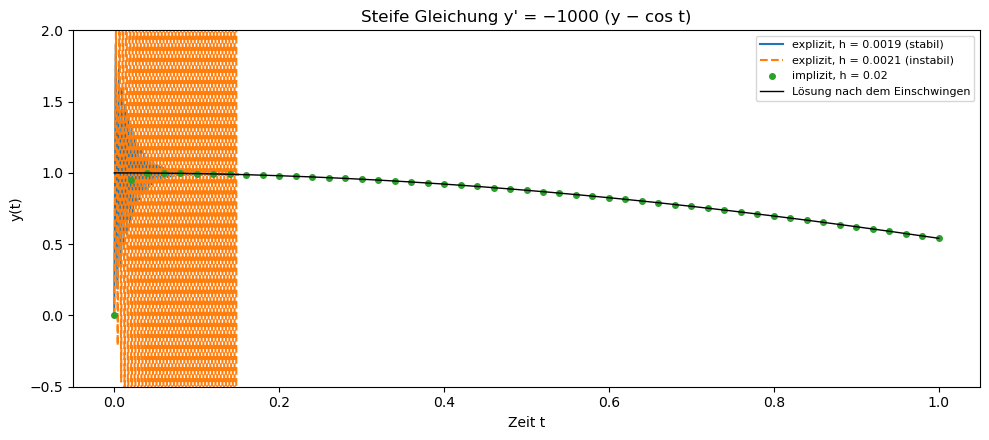

solve_ivp RK45 :  21548 Auswertungen der rechten Seite, Fehler am Ende 4.5e-07
solve_ivp Radau:    624 Auswertungen der rechten Seite, Fehler am Ende 2.1e-08


In [5]:
LAM = 1000.0
f_stiff = lambda t, y: -LAM * (y - np.cos(t))
y_exact = lambda t: (LAM ** 2 * np.cos(t) + LAM * np.sin(t)) / (LAM ** 2 + 1)      # Lösung nach dem Einschwingen

def euler_explicit(h, T=1.0):
    ts = np.arange(0, T + h / 2, h); y = np.empty_like(ts); y[0] = 0.0
    for i in range(len(ts) - 1):
        y[i + 1] = y[i] + h * f_stiff(ts[i], y[i])
    return ts, y

def euler_implicit(h, T=1.0):
    ts = np.arange(0, T + h / 2, h); y = np.empty_like(ts); y[0] = 0.0
    for i in range(len(ts) - 1):                                       # lineare Gleichung, direkt nach y_(n+1) aufgelöst
        y[i + 1] = (y[i] + h * LAM * np.cos(ts[i + 1])) / (1 + h * LAM)
    return ts, y

fig, ax = plt.subplots(figsize=(10, 4.5))
for h, ls in [(0.0019, "-"), (0.0021, "--")]:
    ts, y = euler_explicit(h, 0.15)
    ax.plot(ts, y, ls, label=f"explizit, h = {h} ({'stabil' if h < 2 / LAM else 'instabil'})")
ts, y = euler_implicit(0.02, 1.0)
ax.plot(ts, y, "o", ms=4, label="implizit, h = 0.02")
tt = np.linspace(0, 1, 400)
ax.plot(tt, y_exact(tt), c="black", lw=1, label="Lösung nach dem Einschwingen")
ax.set_ylim(-0.5, 2)
ax.set_xlabel("Zeit t")
ax.set_ylabel("y(t)")
ax.set_title("Steife Gleichung y' = −1000 (y − cos t)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for method in ["RK45", "Radau"]:
    s = solve_ivp(f_stiff, [0, 10], [0.0], method=method, rtol=1e-6, atol=1e-9)
    print(f"solve_ivp {method:5s}: {s.nfev:6d} Auswertungen der rechten Seite, Fehler am Ende {abs(s.y[0, -1] - y_exact(10)):.1e}")

* Das **Bild** zeigt die Lösungen im ersten Zeitabschnitt. Mit $h = 0.0021$ (orange) schwingt das explizite Verfahren immer stärker hin und her und verlässt bald den Bildbereich: Jeder Schritt multipliziert den Fehler mit $1 - 1000h = -1.1$. Mit $h = 0.0019$ (blau, unter den anderen Kurven) bleibt es stabil. Das implizite Verfahren (grüne Punkte) folgt mit zehnmal größerem Schritt sauber der Lösung $\approx\cos t$ (schwarz).
* Die **Ausgabe** zeigt die Kosten: Das explizite RK45 braucht 21 548 Auswertungen der rechten Seite bis $t = 10$, das implizite Radau nur 624, bei kleinerem Fehler ($2\cdot10^{-8}$ statt $5\cdot10^{-7}$). Bei steifen Gleichungen sind implizite Verfahren trotz des Aufwands pro Schritt viel billiger.

##### *5. Ein Eigenwertproblem: der quantenmechanische Oszillator*

Welche Energien erlaubt $-\tfrac12\psi'' + \tfrac12x^2\psi = E\psi$, und wie schnell konvergieren finite Differenzen gegen $E_n = n + \tfrac12$? Vorher vorhersagen: Um welchen Faktor sinkt der Fehler, wenn man $\Delta x$ halbiert?

Die zweite Ableitung wird auf einem Gitter in $[-10, 10]$ durch $(\psi_{j+1} - 2\psi_j + \psi_{j-1})/\Delta x^2$ ersetzt; das macht aus der Gleichung eine tridiagonale Matrix, deren Eigenwerte die Energien sind. Für mehrere Gitterweiten wird der Fehler von $E_3$ gemessen.

**Hintergrund & Fachbegriffe:**
- **Eigenwertproblem:** Die Schrödinger-Gleichung $H\psi = E\psi$ hat normierbare Lösungen nur für bestimmte Energien $E$, die Eigenwerte von $H$.
- **Harmonischer Oszillator:** das Potential $\tfrac12x^2$; seine Energien sind exakt $E_n = n + \tfrac12$ (in Einheiten von $\hbar\omega$), die Eigenfunktionen Hermite-Funktionen.
- **Finite Differenzen:** Ableitungen werden durch Differenzen auf einem Gitter ersetzt; aus dem Differentialoperator wird eine Matrix. Der zentrale 3-Punkte-Stern hat den Fehler $O(\Delta x^2)$.
- **Tridiagonale Matrix:** nur die Haupt- und die beiden Nebendiagonalen sind besetzt; ihre Eigenwerte lassen sich sehr schnell berechnen.

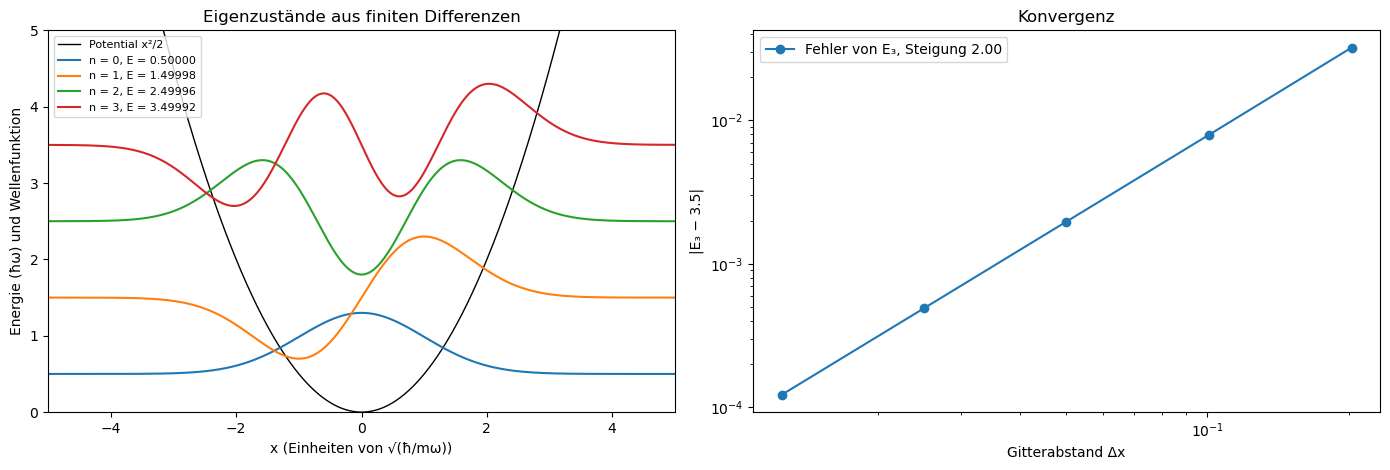

Niedrigste Energien: [0.5     1.49998 2.49996 3.49992 4.49987 5.49981] (exakt 0.5, 1.5, 2.5, …)
Fehler von E₃ fällt wie Δx^2.00


In [6]:
def oscillator_levels(n_points, L=10.0):
    xg = np.linspace(-L, L, n_points)
    dx = xg[1] - xg[0]
    diag = 1 / dx ** 2 + 0.5 * xg ** 2
    off = -0.5 / dx ** 2 * np.ones(n_points - 1)
    E, psi = eigh_tridiagonal(diag, off, select="i", select_range=(0, 5))
    return xg, dx, E, psi

xg, dx, E, psi = oscillator_levels(2000)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(xg, 0.5 * xg ** 2, c="black", lw=1, label="Potential x²/2")
for n in range(4):
    axes[0].plot(xg, E[n] + 0.8 * psi[:, n] / np.max(np.abs(psi[:, n])), label=f"n = {n}, E = {E[n]:.5f}")
axes[0].set_xlim(-5, 5); axes[0].set_ylim(0, 5)
axes[0].set_xlabel("x (Einheiten von √(ħ/mω))")
axes[0].set_ylabel("Energie (ħω) und Wellenfunktion")
axes[0].set_title("Eigenzustände aus finiten Differenzen")
axes[0].legend(fontsize=8)
ns_pts = np.array([100, 200, 400, 800, 1600])
errs, dxs = [], []
for m in ns_pts:
    _, d, Em, _ = oscillator_levels(m)
    dxs.append(d); errs.append(abs(Em[3] - 3.5))
slope = np.polyfit(np.log(dxs), np.log(errs), 1)[0]
axes[1].loglog(dxs, errs, "o-", label=f"Fehler von E₃, Steigung {slope:.2f}")
axes[1].set_xlabel("Gitterabstand Δx")
axes[1].set_ylabel("|E₃ − 3.5|")
axes[1].set_title("Konvergenz")
axes[1].legend()
fig.tight_layout()
plt.show()
print("Niedrigste Energien:", np.round(E, 5), "(exakt 0.5, 1.5, 2.5, …)")
print(f"Fehler von E₃ fällt wie Δx^{slope:.2f}")

* Das **linke Bild** zeigt das Potential und die vier niedrigsten Eigenfunktionen, jede auf der Höhe ihrer Energie gezeichnet. Die $n$-te hat $n$ Nullstellen und reicht etwas über die klassischen Umkehrpunkte hinaus, wo sie exponentiell abklingt (Tunneln in den verbotenen Bereich).
* Das **rechte Bild** zeigt den Fehler von $E_3$ gegen $\Delta x$ doppelt logarithmisch: eine Gerade mit Steigung $2.00$. Halbiert man $\Delta x$, wird der Fehler viermal kleiner.
* Die **Ausgabe** gibt die niedrigsten Energien $0.5, 1.49998, 2.49996, 3.49992, \dots$ Der Fehler wächst mit $n$, weil höhere Zustände stärker schwingen und das Gitter sie schlechter auflöst.

##### *6. Wärmeleitung: Fourier-Reihe gegen finite Differenzen*

Glättet die Wärmeleitung eine Stufe so, wie die Fourier-Reihe es vorhersagt, und was passiert, wenn das explizite Verfahren die Grenze $r\leq1/2$ überschreitet? Vorher vorhersagen: Was geschieht genau an der Grenze $r = 0.5$?

Anfangs ist $u = 1$ in der Mitte des Stabs ($0.25<x<0.75$) und sonst 0, die Enden werden auf 0 gehalten; $\alpha = 1$, 51 Gitterpunkte. Die Fourier-Reihe mit 400 Termen ist die Vergleichslösung, FTCS läuft mit $r = 0.4$, $0.5$ und $0.55$.

**Hintergrund & Fachbegriffe:**
- **Wärmeleitungsgleichung:** $u_t = \alpha u_{xx}$; die Temperatur gleicht sich aus, Wärme fließt von warm nach kalt.
- **Fourier-Reihe:** Die Lösung ist eine Summe von Sinusmoden, die jede mit $e^{-\alpha n^2\pi^2t}$ abklingt; scharfe Kanten bestehen aus vielen hohen Moden und verschwinden deshalb zuerst.
- **FTCS:** vorwärts in der Zeit, zentral im Raum; das einfachste explizite Verfahren.
- **Von-Neumann-Stabilität:** Jede Fourier-Mode auf dem Gitter wird pro Schritt mit einem Faktor $g$ multipliziert; ist $\vert g\vert>1$ für irgendeine Mode, wächst sie und zerstört die Lösung. Hier verlangt das $r = \alpha\Delta t/\Delta x^2\leq\tfrac12$.

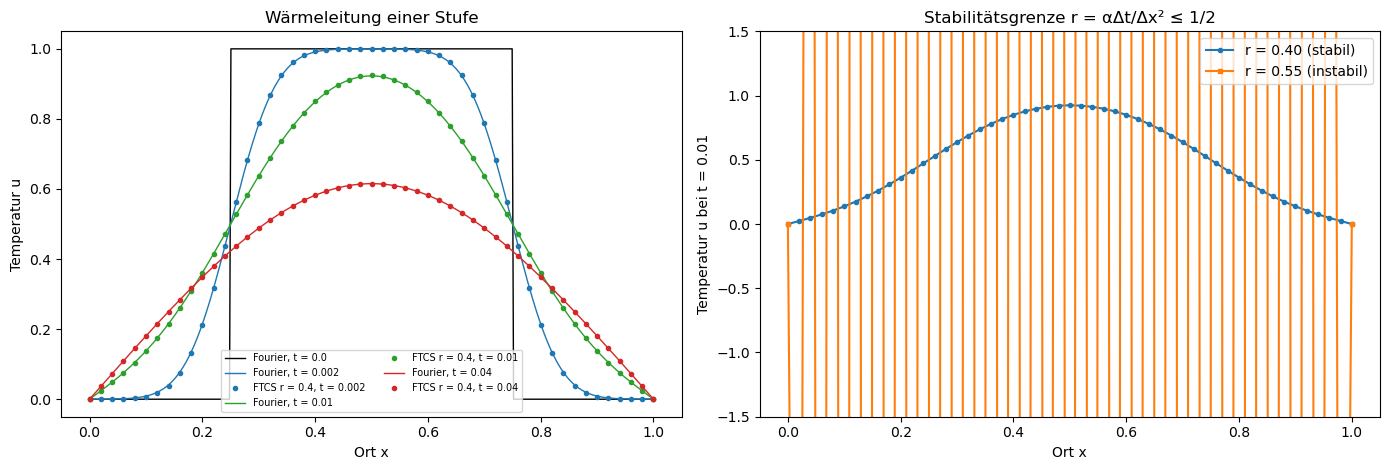

r = 0.4: größte Abweichung von der Fourier-Lösung bei t = 0.04: 1.2e-04
r = 0.5: größte Abweichung von der Fourier-Lösung bei t = 0.04: 1.8e-02
r = 0.55: größte Abweichung von der Fourier-Lösung bei t = 0.04: 4.9e+12


In [7]:
NX = 51
xh = np.linspace(0, 1, NX)
dxh = xh[1] - xh[0]
u0 = ((xh > 0.25) & (xh < 0.75)).astype(float)

def fourier_heat(x, t, n_terms=400):
    n = np.arange(1, n_terms + 1)[:, None]
    bn = 2 / (n * np.pi) * (np.cos(n * np.pi * 0.25) - np.cos(n * np.pi * 0.75))   # b_n der Stufe
    return np.sum(bn * np.sin(n * np.pi * x) * np.exp(-(n * np.pi) ** 2 * t), axis=0)

def ftcs(r, t_end):
    dt = r * dxh ** 2
    u = u0.copy()
    for _ in range(int(round(t_end / dt))):
        u[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
    return u

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
xf = np.linspace(0, 1, 400)
for t_, c in zip([0.0, 0.002, 0.01, 0.04], ["black", "tab:blue", "tab:green", "tab:red"]):
    axes[0].plot(xf, fourier_heat(xf, t_) if t_ > 0 else ((xf > 0.25) & (xf < 0.75)).astype(float), c=c, lw=1, label=f"Fourier, t = {t_}")
    if t_ > 0:
        axes[0].plot(xh, ftcs(0.4, t_), "o", ms=3, c=c, label=f"FTCS r = 0.4, t = {t_}")
axes[0].set_xlabel("Ort x")
axes[0].set_ylabel("Temperatur u")
axes[0].set_title("Wärmeleitung einer Stufe")
axes[0].legend(fontsize=7, ncol=2)
axes[1].plot(xh, ftcs(0.4, 0.01), "o-", ms=3, label="r = 0.40 (stabil)")
axes[1].plot(xh, ftcs(0.55, 0.01), "s-", ms=3, label="r = 0.55 (instabil)")
axes[1].set_ylim(-1.5, 1.5)
axes[1].set_xlabel("Ort x")
axes[1].set_ylabel("Temperatur u bei t = 0.01")
axes[1].set_title("Stabilitätsgrenze r = αΔt/Δx² ≤ 1/2")
axes[1].legend()
fig.tight_layout()
plt.show()
for r in [0.4, 0.5, 0.55]:
    u = ftcs(r, 0.04)
    print(f"r = {r}: größte Abweichung von der Fourier-Lösung bei t = 0.04: {np.max(np.abs(u - fourier_heat(xh, 0.04))):.1e}")

* Das **linke Bild** zeigt die Stufe (schwarz) und ihre Glättung zu den Zeiten 0.002, 0.01 und 0.04: Die Kanten runden sich sofort ab, dann sinkt die Mitte, weil Wärme über die kalten Enden abfließt. Linien sind die Fourier-Reihe, Punkte FTCS mit $r = 0.4$; sie liegen aufeinander.
* Das **rechte Bild** zeigt die Lösung bei $t = 0.01$ mit $r = 0.4$ (stabil, glatt) und $r = 0.55$ (instabil): Die kürzeste Gitterwelle, die von Punkt zu Punkt das Vorzeichen wechselt, ist schon so groß geworden, dass sie das Bild sprengt.
* Die **Ausgabe** gibt die Abweichung bei $t = 0.04$: $1.2\cdot10^{-4}$ für $r = 0.4$, $1.8\cdot10^{-2}$ genau an der Grenze $r = 0.5$, wo die kürzeste Welle nicht gedämpft wird, sondern nur jeden Schritt das Vorzeichen wechselt, und $4.9\cdot10^{12}$ für $r = 0.55$.

##### *7. Die Wellengleichung und die CFL-Bedingung*

Läuft eine gezupfte Saite im Leapfrog-Verfahren so, wie d'Alembert es vorhersagt, und was passiert bei Courant-Zahlen über 1? Vorher vorhersagen: Ist das Verfahren bei $C = 0.9$ genauer oder ungenauer als bei $C = 1$?

Die Saite (Länge 1, $c = 1$, Enden fest) wird bei $x = 0.3$ dreieckig ausgelenkt und losgelassen. Die exakte Lösung ist die Fourier-Reihe der Eigenschwingungen, $u = \sum_nb_n\sin(n\pi x)\cos(n\pi t)$ mit 600 Termen. Leapfrog läuft mit $C = 1$, $0.9$ und $1.02$.

**Hintergrund & Fachbegriffe:**
- **Wellengleichung und d'Alembert-Lösung:** $u_{tt} = c^2u_{xx}$; jede Lösung ist eine nach rechts und eine nach links laufende Form, $F(x - ct) + G(x + ct)$. An festen Enden werden die Wellen mit umgekehrtem Vorzeichen reflektiert.
- **Leapfrog-Verfahren:** berechnet den neuen Zeitschritt aus den zwei vorherigen, zentral in Zeit und Raum.
- **Courant-Zahl und CFL-Bedingung:** $C = c\Delta t/\Delta x$ sagt, wie viele Gitterzellen die Welle pro Zeitschritt läuft; stabil nur für $C\leq1$.
- **Numerische Dispersion:** Auf dem Gitter laufen kurze Wellen mit einer etwas anderen Geschwindigkeit als lange; scharfe Ecken verschmieren dann.

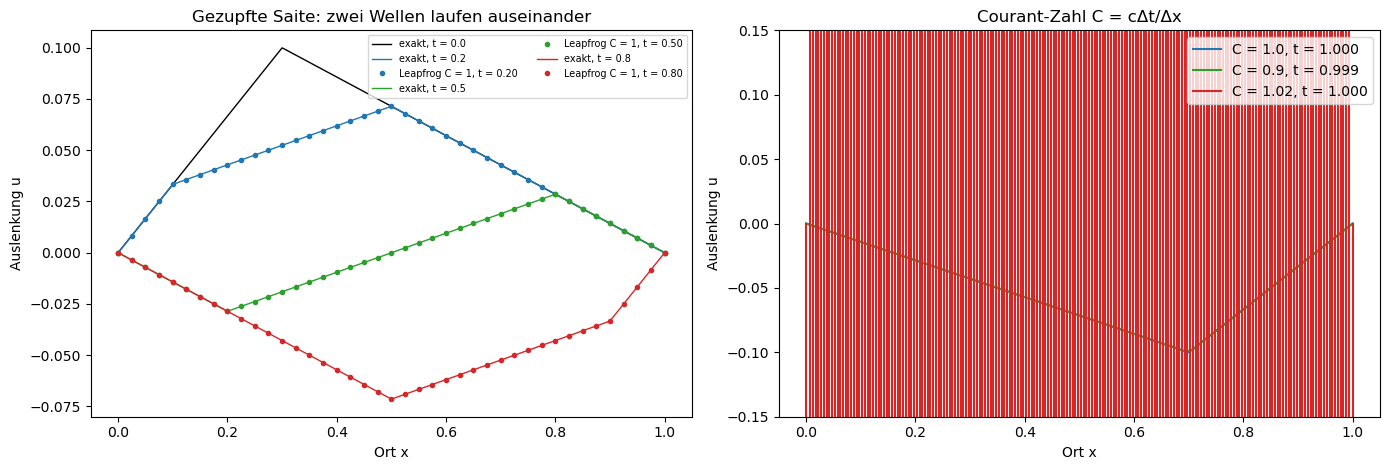

C = 1.0: größte Abweichung von der exakten Lösung bei t = 1.000: 8.0e-05
C = 0.9: größte Abweichung von der exakten Lösung bei t = 0.999: 8.8e-04
C = 1.02: größte Abweichung von der exakten Lösung bei t = 1.000: 5.2e+28


In [8]:
NXW = 201
xw = np.linspace(0, 1, NXW)
dxw = xw[1] - xw[0]
pluck = np.where(xw < 0.3, xw / 0.3, (1 - xw) / 0.7) * 0.1

def wave_exact(x, t, n_terms=600):
    n = np.arange(1, n_terms + 1)[:, None]
    bn = 0.2 * np.sin(n * np.pi * 0.3) / (0.3 * 0.7 * (n * np.pi) ** 2)       # Fourier-Koeffizienten des Dreiecks
    return np.sum(bn * np.sin(n * np.pi * x) * np.cos(n * np.pi * t), axis=0)

def leapfrog(C, t_end):
    dt = C * dxw
    steps = int(round(t_end / dt))
    u_prev = pluck.copy()
    u = pluck.copy()
    u[1:-1] = pluck[1:-1] + 0.5 * C ** 2 * (pluck[2:] - 2 * pluck[1:-1] + pluck[:-2])   # erster Schritt, Anfangsgeschwindigkeit 0
    for _ in range(steps - 1):
        u_new = np.zeros_like(u)
        u_new[1:-1] = 2 * u[1:-1] - u_prev[1:-1] + C ** 2 * (u[2:] - 2 * u[1:-1] + u[:-2])
        u_prev, u = u, u_new
    return u, steps * dt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for t_, c in zip([0.0, 0.2, 0.5, 0.8], ["black", "tab:blue", "tab:green", "tab:red"]):
    axes[0].plot(xw, wave_exact(xw, t_), c=c, lw=1, label=f"exakt, t = {t_}")
    if t_ > 0:
        u, tt_ = leapfrog(1.0, t_)
        axes[0].plot(xw[::5], u[::5], "o", ms=3, c=c, label=f"Leapfrog C = 1, t = {tt_:.2f}")
axes[0].set_xlabel("Ort x")
axes[0].set_ylabel("Auslenkung u")
axes[0].set_title("Gezupfte Saite: zwei Wellen laufen auseinander")
axes[0].legend(fontsize=7, ncol=2)
for C, c in [(1.0, "tab:blue"), (0.9, "tab:green"), (1.02, "tab:red")]:
    u, tt_ = leapfrog(C, 1.0)
    axes[1].plot(xw, u, c=c, label=f"C = {C}, t = {tt_:.3f}")
axes[1].set_ylim(-0.15, 0.15)
axes[1].set_xlabel("Ort x")
axes[1].set_ylabel("Auslenkung u")
axes[1].set_title("Courant-Zahl C = cΔt/Δx")
axes[1].legend()
fig.tight_layout()
plt.show()
for C in [1.0, 0.9, 1.02]:
    u, tt_ = leapfrog(C, 1.0)
    print(f"C = {C}: größte Abweichung von der exakten Lösung bei t = {tt_:.3f}: {np.max(np.abs(u - wave_exact(xw, tt_))):.1e}")

* Das **linke Bild** zeigt die gezupfte Saite: Das Dreieck bei $t = 0$ (schwarz) teilt sich in zwei halb so hohe Formen, die nach links und rechts laufen (blau bei $t = 0.2$), an den Enden mit umgekehrtem Vorzeichen zurückkommen (grün bei $t = 0.5$) und sich bei $t = 0.8$ zu einem umgekehrten Dreieck formen (rot). Die Punkte des Leapfrog-Verfahrens mit $C = 1$ liegen genau auf der exakten Lösung.
* Das **rechte Bild** zeigt die Saite bei $t = 1$ für die drei Courant-Zahlen. $C = 1$ und $C = 0.9$ geben das gespiegelte Dreieck; bei $C = 1.02$ ist die Lösung explodiert und füllt das Bild mit senkrechten Linien.
* Die **Ausgabe** gibt die Abweichungen: $8\cdot10^{-5}$ bei $C = 1$ (das ist nur der Abbruch der Fourier-Reihe, das Verfahren selbst ist dort exakt), $9\cdot10^{-4}$ bei $C = 0.9$ (numerische Dispersion an den Ecken) und $5\cdot10^{28}$ bei $C = 1.02$. Kleinere Zeitschritte sind hier also nicht genauer: $C = 1$ ist optimal.

##### *8. Die Schrödinger-Gleichung: Tunneln durch eine Barriere*

Welcher Anteil eines Wellenpakets mit Energie $E = 0.5$ tunnelt durch eine Barriere der Höhe $0.6$ und Breite 4, und stimmt das mit der exakten Transmission ebener Wellen überein? Vorher vorhersagen: Ist der Anteil größer oder kleiner als die Transmission bei genau $E = 0.5$?

Das Paket ist eine Gaußfunktion mit Breite $\sigma = 10$ und Impuls $k_0 = 1$. Es enthält eine kleine Spanne von Impulsen (Breite $1/2\sigma$); zum Vergleich wird die Transmission $\mathcal T(E)$ aus Abschnitt 5 der Theorie über diese Verteilung gemittelt. Das Split-Step-Verfahren läuft 2601 Schritte; gemessen wird die Wahrscheinlichkeit rechts der Barriere.

**Hintergrund & Fachbegriffe:**
- **Wellenpaket:** eine räumlich begrenzte Welle aus einer Spanne von Impulsen; je breiter im Ort, desto schmaler im Impuls.
- **Tunneleffekt:** Ein Quantenteilchen kommt mit einer gewissen Wahrscheinlichkeit durch eine Barriere, obwohl seine Energie kleiner ist als die Barrierenhöhe; die Wahrscheinlichkeit fällt etwa wie $e^{-2\kappa a}$ mit der Breite $a$.
- **Split-Step-Fourier:** abwechselnd ein halber Schritt mit dem Potential im Ortsraum und ein ganzer mit der kinetischen Energie im Impulsraum, verbunden durch die FFT. Jeder Teilschritt ist unitär, die Norm bleibt erhalten.
- **Transmission:** der Anteil, der durch die Barriere gelangt; für ebene Wellen exakt bekannt, für ein Paket ein Mittel darüber.

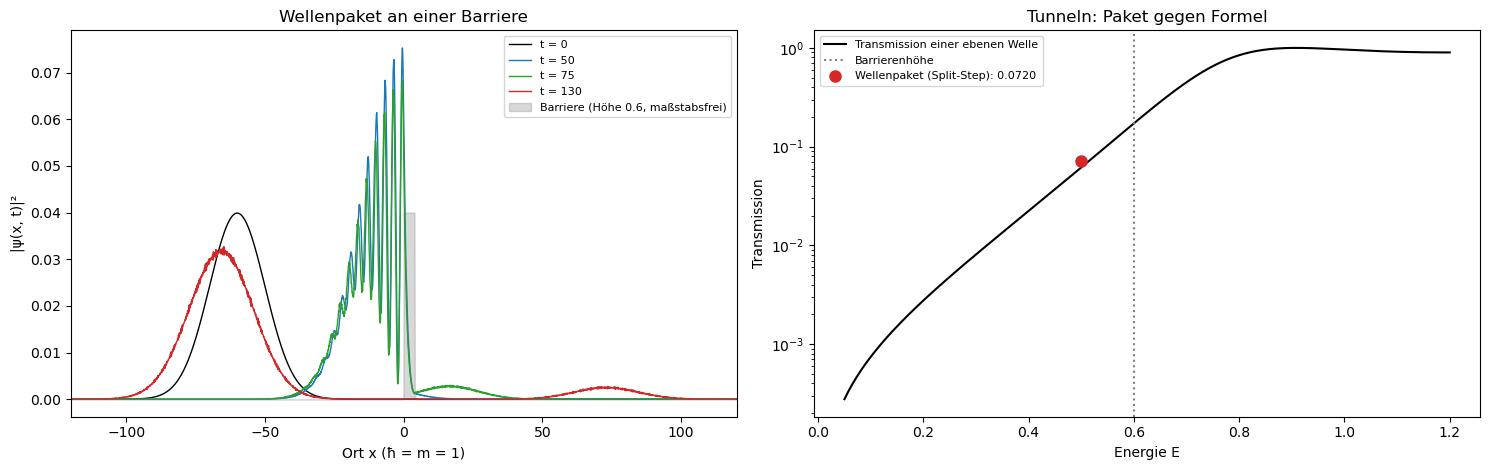

Transmittierter Anteil (Split-Step): 0.0720
Formel bei E = 0.5: 0.0617;  über die Impulsverteilung des Pakets gemittelt: 0.0716
Norm: größte Abweichung von 1 über 2601 Schritte: 1.4e-13


In [9]:
NXS, dxs_ = 4096, 0.1
xs_ = (np.arange(NXS) - NXS // 2) * dxs_            # Gitter so gelegt, dass die Barriere genau 40 Zellen = 4.0 breit ist
k = 2 * np.pi * np.fft.fftfreq(NXS, d=dxs_)
V0, A_BAR, SIG, K0, X0 = 0.6, 4.0, 10.0, 1.0, -60.0
V = np.where((xs_ >= 0) & (xs_ < A_BAR - dxs_ / 2), V0, 0.0)
psi = np.exp(-(xs_ - X0) ** 2 / (4 * SIG ** 2) + 1j * K0 * xs_)
psi /= np.sqrt(np.sum(np.abs(psi) ** 2) * dxs_)

DT, T_END = 0.05, 130.0
half_V = np.exp(-1j * V * DT / 2)
kinetic = np.exp(-1j * k ** 2 / 2 * DT)
snapshots = {}
norms = []
for step in range(int(T_END / DT) + 1):
    t_now = step * DT
    if any(abs(t_now - s) < DT / 2 for s in (0, 50, 75, 130)):
        snapshots[round(t_now)] = np.abs(psi) ** 2
    psi = half_V * np.fft.ifft(kinetic * np.fft.fft(half_V * psi))
    norms.append(np.sum(np.abs(psi) ** 2) * dxs_)
P_trans = np.sum(np.abs(psi[xs_ > A_BAR]) ** 2) * dxs_

def T_plane(E):
    if abs(E - V0) < 1e-12:                          # Grenzfall E = V0
        return 1 / (1 + V0 * A_BAR ** 2 / 2)
    if E < V0:
        kap = np.sqrt(2 * (V0 - E))
        return 1 / (1 + V0 ** 2 * np.sinh(kap * A_BAR) ** 2 / (4 * E * (V0 - E)))
    kp = np.sqrt(2 * (E - V0))
    return 1 / (1 + V0 ** 2 * np.sin(kp * A_BAR) ** 2 / (4 * E * (E - V0)))

kk = np.linspace(K0 - 6 / (2 * SIG), K0 + 6 / (2 * SIG), 2001)
weights = np.exp(-2 * SIG ** 2 * (kk - K0) ** 2)
T_avg = np.sum(weights * np.array([T_plane(q ** 2 / 2) for q in kk])) / np.sum(weights)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for (t_, dens), c in zip(sorted(snapshots.items()), ["black", "tab:blue", "tab:green", "tab:red"]):
    axes[0].plot(xs_, dens, c=c, lw=1, label=f"t = {t_}")
axes[0].fill_between(xs_, 0, V / V0 * 0.04, color="grey", alpha=0.3, label="Barriere (Höhe 0.6, maßstabsfrei)")
axes[0].set_xlim(-120, 120)
axes[0].set_xlabel("Ort x (ħ = m = 1)")
axes[0].set_ylabel("|ψ(x, t)|²")
axes[0].set_title("Wellenpaket an einer Barriere")
axes[0].legend(fontsize=8)
EE = np.linspace(0.05, 1.2, 300)
axes[1].semilogy(EE, [T_plane(e) for e in EE], c="black", label="Transmission einer ebenen Welle")
axes[1].axvline(V0, color="grey", ls=":", label="Barrierenhöhe")
axes[1].plot([K0 ** 2 / 2], [P_trans], "o", c="tab:red", ms=8, label=f"Wellenpaket (Split-Step): {P_trans:.4f}")
axes[1].set_xlabel("Energie E")
axes[1].set_ylabel("Transmission")
axes[1].set_title("Tunneln: Paket gegen Formel")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"Transmittierter Anteil (Split-Step): {P_trans:.4f}")
print(f"Formel bei E = 0.5: {T_plane(0.5):.4f};  über die Impulsverteilung des Pakets gemittelt: {T_avg:.4f}")
print(f"Norm: größte Abweichung von 1 über {len(norms)} Schritte: {np.max(np.abs(np.array(norms) - 1)):.1e}")

* Das **linke Bild** zeigt die Wahrscheinlichkeitsdichte zu vier Zeiten. Das Paket (schwarz, $t = 0$) läuft nach rechts auf die Barriere (grau) zu. Dort überlagern sich einlaufende und reflektierte Welle zu dichten Interferenzstreifen ($t = 50$, $75$). Danach läuft der größte Teil nach links zurück (rot, $t = 130$), ein kleiner Teil ist durchgetunnelt und läuft rechts weiter.
* Das **rechte Bild** zeigt die Transmission ebener Wellen gegen die Energie (logarithmische Achse): unterhalb der Barrierenhöhe $0.6$ steigt sie steil an, oberhalb ist sie fast 1. Der rote Punkt ist das Wellenpaket mit $0.0720$; er liegt etwas über der Kurve bei $E = 0.5$.
* Die **Ausgabe** erklärt den Unterschied: Die Formel gibt bei $E = 0.5$ nur $0.0617$, über die Impulsverteilung des Pakets gemittelt aber $0.0716$, fast genau den simulierten Wert. Die energiereicheren Anteile des Pakets tunneln viel leichter und heben den Mittelwert. Die Norm bleibt über 2601 Schritte auf $1.4\cdot10^{-13}$ erhalten.

##### *9. Floquet-Theorie: die Stabilitätskarte der Mathieu-Gleichung*

Für welche Werte von $a$ und $q$ bleiben die Lösungen von $\ddot x + (a - 2q\cos2t)x = 0$ beschränkt, und beginnen die instabilen Zungen bei $a = n^2$? Vorher vorhersagen: Warum ist die Zunge bei $a = 9$ für kleine $q$ kaum zu sehen?

Für jedes Paar $(a, q)$ auf einem Gitter werden zwei Grundlösungen über eine Periode $\pi$ integriert (vektorisiertes Runge–Kutta, alle Gitterpunkte zugleich). Daraus folgen die Monodromiematrix und ihre Spur (Abschnitt 6 der Theorie); rot ist instabil.

**Hintergrund & Fachbegriffe:**
- **Mathieu-Gleichung:** ein Oszillator, dessen Federkonstante periodisch schwankt; $a$ ist das Quadrat der Eigenfrequenz, $q$ die Stärke der Modulation. Beispiele: eine Schaukel, Ionen in einer Paul-Falle.
- **Monodromiematrix:** bildet Ort und Geschwindigkeit über eine Periode der Modulation ab; ihre Eigenwerte sagen, ob Lösungen wachsen.
- **Floquet-Theorie:** Bei periodischen Koeffizienten zerfallen die Lösungen in Faktoren $\mu^{t/T}$ mal periodische Funktionen; $\vert\mathrm{tr}\,M\vert<2$ heißt beschränkt, $\vert\mathrm{tr}\,M\vert>2$ exponentielles Wachstum.
- **Parametrische Resonanz:** Aufschaukeln durch periodisches Verändern eines Parameters statt durch eine äußere Kraft, am stärksten bei der doppelten Eigenfrequenz.

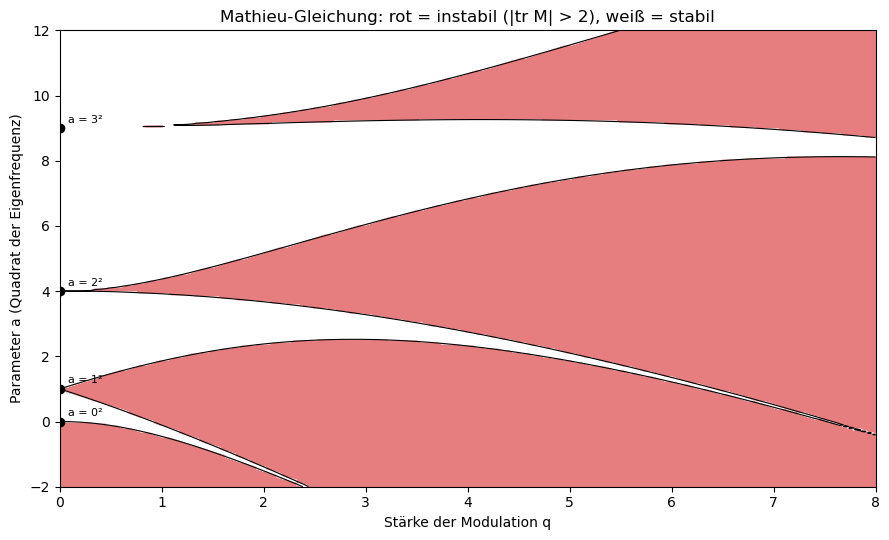

Determinante der Monodromiematrix: 0.9999999997 bis 1.0000000000 (Theorie 1)
Instabile Bereiche bei q = 2: a ∈ [-2.00, -1.55], a ∈ [-1.35, 2.35], a ∈ [3.70, 5.15], a ∈ [9.15, 9.35]


In [10]:
a_vals = np.linspace(-2, 12, 281)
q_vals = np.linspace(0, 8, 161)
Aa, Qq = np.meshgrid(a_vals, q_vals)
a_flat, q_flat = Aa.ravel(), Qq.ravel()

def mathieu_rhs(t, Y):
    x1, v1, x2, v2 = Y
    w2 = a_flat - 2 * q_flat * np.cos(2 * t)
    return np.array([v1, -w2 * x1, v2, -w2 * x2])

Y = np.array([np.ones_like(a_flat), np.zeros_like(a_flat), np.zeros_like(a_flat), np.ones_like(a_flat)])
n_steps = 800
h = np.pi / n_steps
for i in range(n_steps):
    Y = rk4(mathieu_rhs, i * h, Y, h)
trace = (Y[0] + Y[3]).reshape(Aa.shape)                 # tr M = x1(π) + v2(π)
det = (Y[0] * Y[3] - Y[1] * Y[2]).reshape(Aa.shape)     # sollte 1 sein
stable = np.abs(trace) < 2

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.contourf(Qq, Aa, stable, levels=[-0.5, 0.5, 1.5], colors=["tab:red", "white"], alpha=0.6)
ax.contour(Qq, Aa, np.abs(trace) - 2, levels=[0], colors="black", linewidths=0.8)
for n in range(4):
    ax.plot(0, n ** 2, "o", c="black", ms=6)
    ax.annotate(f"a = {n}²", (0, n ** 2), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Stärke der Modulation q")
ax.set_ylabel("Parameter a (Quadrat der Eigenfrequenz)")
ax.set_title("Mathieu-Gleichung: rot = instabil (|tr M| > 2), weiß = stabil")
fig.tight_layout()
plt.show()
print(f"Determinante der Monodromiematrix: {det.min():.10f} bis {det.max():.10f} (Theorie 1)")
row = ~stable[np.argmin(np.abs(q_vals - 2.0))]                  # instabile a-Werte bei q = 2
edges = np.flatnonzero(np.diff(np.r_[0, row.astype(int), 0]))
print("Instabile Bereiche bei q = 2:", ", ".join(f"a ∈ [{a_vals[s]:.2f}, {a_vals[e - 1]:.2f}]" for s, e in zip(edges[::2], edges[1::2])))

* Das **Bild** zeigt die Stabilitätskarte in der $(q, a)$-Ebene: rote Zungen sind instabil, weiße Bereiche stabil. Die Zungen beginnen bei $q = 0$ genau an den Punkten $a = 0, 1, 4, 9$, also $a = n^2$, und werden mit wachsendem $q$ breiter. Die Zunge bei $a = 1$ ist die stärkste: Dort schwingt der Parameter mit der doppelten Eigenfrequenz.
* Die Zunge bei $a = 9$ beginnt erst bei $q\approx1$ sichtbar zu werden, weil die $n$-te Zunge für kleine $q$ nur etwa $q^n$ breit ist und durch das Gitter fällt. Bei großem $q$ verschmelzen die Zungen fast.
* Die **Ausgabe** bestätigt $\det M = 1$ bis auf $3\cdot10^{-10}$ (Liouville) und gibt die instabilen Bereiche bei $q = 2$: $a\in[-1.35, 2.35]$, $[3.70, 5.15]$ und $[9.15, 9.35]$ (dazu der Bereich unterhalb von $-1.55$), in Übereinstimmung mit den tabellierten Mathieu-Eigenwerten.

#### **Ergebnis**

Beim Lauf vom 2026-10-12:

- **Exakte Lösungen:** sympy findet $\lambda = -\gamma \pm \sqrt{\gamma^2 - \omega_0^2}$ für den gedämpften Oszillator, $(C_1 + C_2t)e^{-\omega_0 t}$ im aperiodischen Grenzfall und $N(t) = KN_0e^{rt}/(K + N_0(e^{rt} - 1))$ für die logistische Gleichung; das Einsetzen bestätigt alle drei.
- **Lineare Systeme:** $e^{At}x_0$ und die numerische Lösung stimmen auf etwa $10^{-10}$ überein. Spur und Determinante sagen die Form der Bahnen richtig voraus: Sattel bei $\Delta < 0$, Spiralen bei $\tau^2 < 4\Delta$, Zentrum bei $\tau = 0$.
- **Integratoren:** Mit $h = 0.1$ wächst die Energie beim expliziten Euler-Verfahren in 200 Zeiteinheiten um den Faktor $4.4\cdot10^8$, genau $(1 + h^2)^{T/h}$. Die symplektischen Verfahren halten sie für alle Zeiten in einem schmalen Band (Euler ±5 %, Störmer-Verlet ±0.2 %). Runge-Kutta 4 ist pro Schritt viel genauer, aber nicht symplektisch: Seine Energie driftet langsam und stetig, hier um $10^{-5}$. Die gemessenen Ordnungen sind 1.04, 1.01, 2.00 und 3.98.
- **Steife Gleichung:** Das explizite Euler-Verfahren ist bei $h = 0.0019$ stabil und explodiert bei $h = 0.0021$, genau an der Grenze $2/1000$; das implizite Verfahren läuft mit $h = 0.02$ problemlos. Mit adaptiver Schrittweite braucht das explizite RK45 21 548 Auswertungen, das implizite Radau 624.
- **Eigenwerte:** Die finiten Differenzen geben $0.5, 1.49998, 2.49996, \dots$; der Fehler fällt wie $\Delta x^2$.
- **Wärmeleitung:** Mit $r = 0.4$ weicht FTCS um $10^{-4}$ von der Fourier-Reihe ab. An der Grenze $r = 0.5$ wird die kürzeste Gitterwelle nicht gedämpft, sondern wechselt nur das Vorzeichen (Abweichung $2\cdot10^{-2}$); bei $r = 0.55$ wächst sie, und die Lösung explodiert ($5\cdot10^{12}$).
- **Welle:** Bei $C = 1$ ist das Leapfrog-Verfahren auf dem Gitter exakt; die Abweichung von $8\cdot10^{-5}$ stammt vom Abbruch der Fourier-Reihe der Vergleichslösung. Bei $C = 0.9$ laufen kurze Wellen etwas zu langsam (Dispersion, Abweichung $9\cdot10^{-4}$); bei $C = 1.02$ explodiert die Lösung.
- **Tunneln:** Das Split-Step-Verfahren gibt einen transmittierten Anteil von 0.0720; die Formel, über die Impulsverteilung des Pakets gemittelt, gibt 0.0716. Die Formel bei der mittleren Energie allein gibt nur 0.0617: Die energiereicheren Anteile des Pakets tunneln viel leichter und heben den Mittelwert. Die Norm bleibt auf $10^{-13}$ erhalten. Wichtig war, das Gitter so zu legen, dass die Barriere genau 4.0 breit ist; mit 3.9 tunnelten 7 % mehr.
- **Mathieu-Gleichung:** $\det M = 1$ bis auf $3\cdot10^{-10}$. Die instabilen Zungen beginnen bei $a = 0, 1, 4, 9$; bei $q = 2$ sind $a \in [-1.35, 2.35]$, $[3.70, 5.15]$ und $[9.15, 9.35]$ instabil, in Übereinstimmung mit den tabellierten Mathieu-Eigenwerten. Für kleine $q$ ist die $n$-te Zunge nur etwa $q^n$ breit; deshalb ist die Zunge bei $a = 9$ erst ab $q \approx 1$ auf dem Gitter zu sehen.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Nicht eindeutig:** Löse $\dot y = \sqrt{|y|}$ mit $y(0) = 0$ numerisch. Welche der beiden Lösungen findet das Verfahren, und was passiert mit $y(0) = 10^{-12}$?
2. **Implizite Wärmeleitung:** Ersetze FTCS durch das Crank-Nicolson-Verfahren (Mittel aus explizitem und implizitem Schritt, eine tridiagonale Gleichung pro Schritt). *(Vorhersage: stabil für jedes $r$, Ordnung 2 in der Zeit.)*
3. **Kepler-Bahn:** Integriere eine elliptische Planetenbahn über 1000 Umläufe mit Runge-Kutta 4 und mit Störmer-Verlet bei gleicher Schrittweite. Welches Verfahren hält die Bahn, und welches lässt sie langsam schrumpfen oder wachsen?
4. **Energie über der Barriere:** Setze in Experiment 8 $k_0 = 1.2$ ($E = 0.72 > V_0$). Wird alles transmittiert? *(Vorhersage: nein, ein Teil wird auch über der Barriere reflektiert, außer bei Resonanzen mit $k'a = n\pi$.)*
5. **Gedämpfte Schaukel:** Füge der Mathieu-Gleichung eine Dämpfung $2\gamma\dot x$ hinzu. Wie verändern sich die Zungen nahe $q = 0$?

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Wann hat ein Anfangswertproblem genau eine Lösung, und was ist ein Gegenbeispiel?</summary>

Wenn $f$ stetig ist und in $y$ einer Lipschitz-Bedingung genügt (Picard–Lindelöf). $\dot y = \sqrt y$, $y(0) = 0$ hat die Lösungen $0$ und $t^2/4$.
</details>

<details><summary>2. Wie liest man aus Spur und Determinante den Typ eines linearen Fixpunkts in der Ebene ab?</summary>

$\Delta<0$: Sattel. $\Delta>0$ und $\tau^2<4\Delta$: Spirale (stabil für $\tau<0$), $\tau = 0$: Zentrum. $\Delta>0$ und $\tau^2>4\Delta$: Knoten.
</details>

<details><summary>3. Was ist der aperiodische Grenzfall?</summary>

$\gamma = \omega_0$: Die beiden Exponenten fallen zusammen, die Lösung ist $(c_1 + c_2t)e^{-\gamma t}$, die schnellste Rückkehr in die Ruhelage ohne Überschwingen.
</details>

<details><summary>4. Was bedeutet Ordnung 4 bei Runge–Kutta, und wie misst man sie?</summary>

Der Fehler am Ende fällt wie $h^4$. Man trägt den Fehler gegen $h$ doppelt logarithmisch auf; die Steigung ist die Ordnung.
</details>

<details><summary>5. Warum explodiert die Energie beim expliziten Euler-Verfahren, und warum nicht beim symplektischen?</summary>

Ein Euler-Schritt für den Oszillator hat die Determinante $1 + h^2$ und vergrößert Flächen im Phasenraum, die Energie wächst wie $e^{ht}$. Der symplektische Schritt hat Determinante 1 und erhält eine leicht veränderte Energie exakt; die echte schwankt nur um $O(h)$.
</details>

<details><summary>6. Was ist eine steife Gleichung, und welche Verfahren eignen sich?</summary>

Eine Gleichung mit einer sehr schnellen und einer langsamen Zeitskala. Explizite Verfahren brauchen Schritte unterhalb der schnellen Skala ($h\leq2/\vert\lambda\vert$), implizite (Radau, implizites Euler) nicht.
</details>

<details><summary>7. Wie wird ein Eigenwertproblem zu einer Matrix, und wie genau ist das?</summary>

Man ersetzt die zweite Ableitung durch den 3-Punkte-Stern auf einem Gitter; die Gleichung wird zu einer tridiagonalen Matrix, deren Eigenwerte die Energien nähern. Der Fehler fällt wie $\Delta x^2$.
</details>

<details><summary>8. Woran erkennt man elliptische, parabolische und hyperbolische Gleichungen, und wie verhalten sie sich?</summary>

Am Vorzeichen von $B^2 - AC$: negativ, null, positiv. Elliptisch: Gleichgewicht, glatt. Parabolisch: Ausgleich, Kanten verschwinden sofort. Hyperbolisch: Ausbreitung mit endlicher Geschwindigkeit, Kanten bleiben.
</details>

<details><summary>9. Warum glättet die Wärmeleitung Kanten sofort?</summary>

In der Fourier-Reihe klingt die $n$-te Mode wie $e^{-\alpha n^2\pi^2t}$ ab; Kanten bestehen aus hohen Moden, die am schnellsten verschwinden.
</details>

<details><summary>10. Woher kommt die Bedingung r ≤ 1/2 für das explizite Wärmeleitungsverfahren?</summary>

Aus der von-Neumann-Analyse: Die kürzeste Gitterwelle wird pro Schritt mit $1 - 4r$ multipliziert; für $\vert1 - 4r\vert\leq1$ muss $r\leq\tfrac12$ sein.
</details>

<details><summary>11. Was sagt die CFL-Bedingung, und warum ist Leapfrog bei C = 1 exakt?</summary>

$C = c\Delta t/\Delta x\leq1$: Die Welle darf pro Schritt nicht weiter als eine Zelle laufen. Bei $C = 1$ laufen die Charakteristiken genau durch Gitterpunkte, und das Verfahren reproduziert d'Alembert exakt.
</details>

<details><summary>12. Warum erhält das Split-Step-Verfahren die Norm, und welchen Fehler macht es?</summary>

Jeder Teilschritt ist eine Multiplikation mit einer Phase, im Ort- oder im Impulsraum, also unitär. Die symmetrische Zerlegung macht pro Schritt einen Fehler $O(\Delta t^3)$, weil sich der Fehler zweiter Ordnung weghebt.
</details>

<details><summary>13. Wann sind die Lösungen einer Gleichung mit periodischem Koeffizienten beschränkt?</summary>

Wenn die Spur der Monodromiematrix betragsmäßig kleiner als 2 ist; dann liegen ihre Eigenwerte auf dem Einheitskreis. Bei der Mathieu-Gleichung beginnen die instabilen Zungen bei $a = n^2$.
</details>

#### **Nächste Schritte**

- **Elliptische Gleichungen:** Laplace- und Poisson-Gleichung in zwei Dimensionen mit Relaxationsverfahren und mit dem Mehrgitterverfahren; Elektrostatik und stationäre Wärmeverteilung.
- **Spektralmethoden und finite Elemente:** Lösungen in einer Basis glatter Funktionen (Fourier, Chebyshev) konvergieren schneller als jede Potenz von $\Delta x$; finite Elemente erlauben beliebige Geometrien.
- **Nichtlineare Wellen:** Die Korteweg-de-Vries-Gleichung hat Solitonen, die sich durchdringen, ohne ihre Form zu ändern; die nichtlineare Schrödinger-Gleichung beschreibt Pulse in Glasfasern. Beide lassen sich mit dem Split-Step-Verfahren aus Experiment 8 lösen.
- **Stochastische Differentialgleichungen:** Brownsche Bewegung und das Euler-Maruyama-Verfahren.
- **Verbindungen:** Phasenraum und Stabilität nichtlinearer Systeme (Notebook `chaos.ipynb`), die Variationsrechnung als Quelle vieler Gleichungen (Notebook `calculus_of_variations.ipynb`).

#### **Referenzen**

- Boyce, W. E. & DiPrima, R. C. (2012): *Elementary Differential Equations and Boundary Value Problems*, 10th ed., Wiley (ODE, Trennung der Variablen, Fourier-Reihen).
- Hairer, E., Lubich, C. & Wanner, G. (2006): *Geometric Numerical Integration*, 2nd ed., Springer (symplektische Verfahren, Kap. I und VI).
- Hairer, E. & Wanner, G. (1996): *Solving Ordinary Differential Equations II: Stiff and Differential-Algebraic Problems*, 2nd ed., Springer.
- LeVeque, R. J. (2007): *Finite Difference Methods for Ordinary and Partial Differential Equations*, SIAM (von-Neumann-Analyse, CFL-Bedingung).
- Press, W. H. et al. (2007): *Numerical Recipes*, 3rd ed., Cambridge University Press, Kap. 17 und 20.
- Courant, R., Friedrichs, K. & Lewy, H. (1928): *Über die partiellen Differenzengleichungen der mathematischen Physik*, Math. Ann. 100, 32.
- Magnus, W. & Winkler, S. (1966): *Hill's Equation*, Wiley (Floquet-Theorie, Mathieu-Gleichung).